**Domain – Automotive**

**focus – Incentivize drivers**

**Business challenge/requirement**

Lithionpower is the largest provider of electric vehicle(e-vehicle) batteries.  It provides battery on a rental model to e-vehicle drivers. Drivers rent battery typically for a day and then replace it with a charged battery from the company.

Lithionpower has a variable pricing model based on the driver's driving history. As the life of a battery depends on factors such as overspeeding, distance drivingper day,etc.

You as anML expert haveto create a cluster model where drivers can be grouped based on the driving data.

**Key issues**

Drivers will be incentivized based on the cluster, so grouping has to be accurate

**Considerations**

NONE

**Data volume**
- 4000 records – file driver-data.csv
Fields in Data
- id: Unique Id of the driver
- mean_dist_day: Mean distance driven by driver per day
- mean_over_speed_perc: Mean percentage of time a driver was > 5 mph over the speed limit

**Additional information**

-NA

**Business benefits**

Increase in profits,up to 15-20% as drivers with poor history will be charged more

In [3]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv('/content/driver-data.csv')
df.columns

Index(['id', 'mean_dist_day', 'mean_over_speed_perc'], dtype='object')

In [5]:
cluster_interia = list()
num = np.arange(1, 11)
for n in num :
    kmeans = KMeans(n_clusters=n, random_state=42)
    kmeans.fit(df[['mean_dist_day', 'mean_over_speed_perc']])
    cluster_interia.append(kmeans.inertia_)

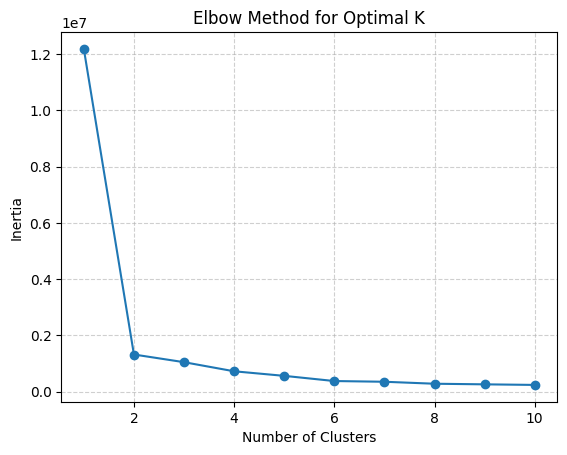

In [17]:
plt.plot(num, cluster_interia, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

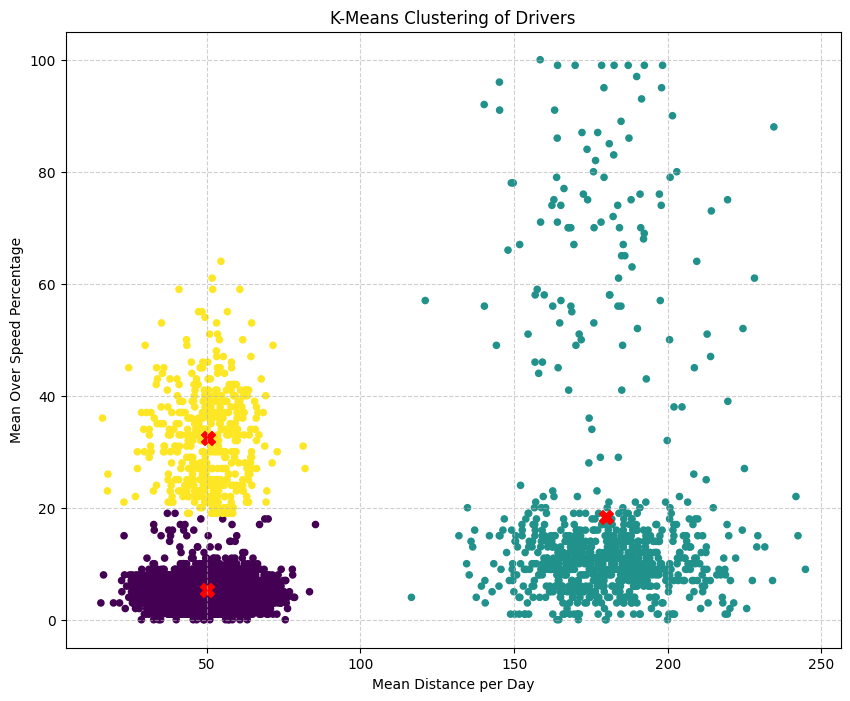

In [18]:
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(df[['mean_dist_day', 'mean_over_speed_perc']])
df['cluster'] = kmeans.labels_
sk_centroids = kmeans.cluster_centers_

plt.figure(figsize=(10, 8))
plt.scatter(df['mean_dist_day'], df['mean_over_speed_perc'], c=df['cluster'], cmap='viridis', s=20)
plt.scatter(sk_centroids[:, 0], sk_centroids[:, 1], marker='X', s=100, color='red')
plt.xlabel('Mean Distance per Day')
plt.ylabel('Mean Over Speed Percentage')
plt.title('K-Means Clustering of Drivers')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [15]:
# Analyze cluster characteristics
cluster_summary = df.groupby('cluster')[['mean_dist_day', 'mean_over_speed_perc']].mean()
print("Cluster Mean Characteristics:")
print(cluster_summary)

Cluster Mean Characteristics:
         mean_dist_day  mean_over_speed_perc
cluster                                     
0            49.984285              5.214414
1           180.017075             18.290000
2            50.461271             32.428235


### Cluster Interpretation

Based on the K-Means clustering and the mean characteristics of each cluster, we can interpret the groups as follows:

*   **Cluster 0 (e.g., Low Distance, Low Overspeed):** Drivers in this cluster typically cover shorter distances per day and have a low percentage of overspeeding. These could be considered 'safe' or 'low-usage' drivers.

*   **Cluster 1 (e.g., High Distance, Moderate Overspeed):** This cluster likely represents drivers who cover significant distances daily, but their overspeeding percentage is still relatively moderate. These might be professional drivers who cover long routes.

*   **Cluster 2 (e.g., Moderate Distance, High Overspeed):** Drivers in this group might drive moderate distances but exhibit a higher tendency for overspeeding. These could be considered 'risky' drivers, potentially requiring higher battery rental charges.

*(Note: The exact cluster numbers (0, 1, 2) can vary depending on the KMeans initialization, but their characteristics will remain distinct. Refer to the 'Cluster Mean Characteristics' output above for precise values.)*